# 01. Inventario de los datos y carga con Dask

**Puntos de la rúbrica:** a (identificar el conjunto de datos) y e (Dask con al menos dos configuraciones de workers y memoria por worker).

## Para qué sirve este notebook

Los datos son 21 archivos ZIP (uno por día) con millones de validaciones de la troncal de TransMilenio. Son demasiado pesados para trabajarlos cómodamente con pandas, así que este notebook hace tres cosas:

1. **Inventario:** cuánto pesa cada archivo, cuántas filas y columnas tiene y qué trae.
2. **Tiempos de carga:** cuánto tarda y cuánta memoria usa leer un archivo, y comparar **Dask con distintas configuraciones** de workers y memoria por worker.
3. **Consolidado:** dejar **todos los datos en una sola tabla en formato Parquet** (una carpeta que se lee como un solo archivo). Ese consolidado es el punto de partida de todo el análisis posterior.

> Se avanza **un paso a la vez**: cada sección se revisa antes de pasar a la siguiente.

## 1. Inventario de archivos

Primero se mira lo que hay en `data/raw/validaciones_troncal/`: cuántos archivos son, qué día corresponde a cada uno y cuánto pesan **comprimidos** (el ZIP en el disco) y **descomprimidos** (el CSV que hay dentro, que es lo que realmente se tiene que leer).

In [1]:
# QUÉ HACE: lista los archivos de validaciones y mide cuánto pesa cada uno comprimido (ZIP) y descomprimido (CSV).
# CÓMO: lee solo el "índice" de cada ZIP (no abre el CSV), por eso es instantáneo; la fecha sale del nombre del archivo.
# QUÉ MIRAR: 21 archivos; ~2.1 GB comprimidos que se vuelven ~10.3 GB; el festivo (7-ago) y los fines de semana pesan mucho menos.
import zipfile
from pathlib import Path
import pandas as pd

RAW = Path('../data/raw/validaciones_troncal')
DIAS = {0: 'lunes', 1: 'martes', 2: 'miércoles', 3: 'jueves', 4: 'viernes', 5: 'sábado', 6: 'domingo'}

filas = []
for ruta in sorted(RAW.glob('validacionTroncal*.zip')):
    with zipfile.ZipFile(ruta) as z:
        contenido = z.infolist()          # lo que hay dentro del ZIP
        csv = contenido[0]
    fecha = pd.to_datetime(ruta.stem[-8:], format='%Y%m%d')
    filas.append({'archivo': ruta.name, 'fecha': fecha.date(), 'día': DIAS[fecha.dayofweek],
                  'archivos_dentro': len(contenido), 'zip_MB': ruta.stat().st_size / 1e6,
                  'csv_MB': csv.file_size / 1e6, 'veces_que_se_expande': csv.file_size / ruta.stat().st_size})

inventario = pd.DataFrame(filas)
display(inventario.round(1))

print(f"Archivos: {len(inventario)}")
print(f"Peso comprimido (ZIP):   {inventario.zip_MB.sum() / 1e3:.2f} GB")
print(f"Peso descomprimido (CSV): {inventario.csv_MB.sum() / 1e3:.2f} GB  (el ZIP se expande ~{inventario.veces_que_se_expande.mean():.1f} veces)")
print(f"Cada ZIP trae {inventario.archivos_dentro.unique().tolist()} archivo(s) dentro")

,archivo,fecha,día,archivos_dentro,zip_MB,csv_MB,veces_que_se_expande
0,validacionTroncal20260803.zip,2026-08-03,lunes,1,123.4,594.6,4.8
1,validacionTroncal20260804.zip,2026-08-04,martes,1,127.6,615.1,4.8
2,validacionTroncal20260805.zip,2026-08-05,miércoles,1,128.4,619.4,4.8
3,validacionTroncal20260806.zip,2026-08-06,jueves,1,124.5,601.3,4.8
4,validacionTroncal20260807.zip,2026-08-07,viernes,1,33.8,173.4,5.1
5,validacionTroncal20260808.zip,2026-08-08,sábado,1,69.9,349.3,5.0
6,validacionTroncal20260809.zip,2026-08-09,domingo,1,32.7,170.4,5.2
7,validacionTroncal20260810.zip,2026-08-10,lunes,1,118.8,573.2,4.8
8,validacionTroncal20260811.zip,2026-08-11,martes,1,124.2,599.6,4.8
9,validacionTroncal20260812.zip,2026-08-12,miércoles,1,125.5,606.0,4.8


Archivos: 21
Peso comprimido (ZIP):   2.12 GB
Peso descomprimido (CSV): 10.33 GB  (el ZIP se expande ~4.9 veces)
Cada ZIP trae [1] archivo(s) dentro


## 2. Leer un archivo con pandas (la línea base)

Antes de usar Dask hay que saber **cuánto cuesta leer un archivo "a la manera normal"**. Se toma un día hábil típico y se mide:

- cuántas filas y columnas tiene,
- cuánto **tarda** en cargarse,
- cuánta **memoria** ocupa (en el computador, no en el disco: un CSV de 600 MB puede ocupar varios GB en memoria).

Estas cifras son la **línea base**: más adelante se comparan contra Dask para ver cuánto ayuda.

In [2]:
# QUÉ HACE: carga un día completo (martes 15-sep, de los más pesados) con pandas y mide tiempo y memoria.
# CÓMO: pd.read_csv lee el CSV dentro del ZIP; time.perf_counter mide los segundos; psutil mide la memoria que usa este proceso.
# QUÉ MIRAR: ~1.9 millones de filas y 22 columnas; la memoria en el computador es varias veces el tamaño del CSV (600 MB).
import time, os
import psutil

ARCHIVO = RAW / 'validacionTroncal20260915.zip'
proceso = psutil.Process(os.getpid())
memoria_antes = proceso.memory_info().rss / 1e9           # GB que usaba el notebook antes de leer

t0 = time.perf_counter()
df = pd.read_csv(ARCHIVO, compression='zip', encoding='utf-8', low_memory=False)
segundos = time.perf_counter() - t0

memoria_despues = proceso.memory_info().rss / 1e9
print(f"Archivo: {ARCHIVO.name}  ({ARCHIVO.stat().st_size / 1e6:.0f} MB ZIP)")
print(f"Filas: {len(df):,} | Columnas: {df.shape[1]}")
print(f"Tiempo de lectura (pandas, 1 proceso): {segundos:.1f} s  ->  {len(df) / segundos:,.0f} filas por segundo")
print(f"Memoria que ocupa la tabla: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
print(f"Memoria del notebook: {memoria_antes:.2f} GB antes -> {memoria_despues:.2f} GB después")
print(f"Proyección para los 21 días leyendo uno tras otro: ~{segundos * 21 / 60:.1f} minutos (los fines de semana son más livianos)")

Archivo: validacionTroncal20260915.zip  (129 MB ZIP)
Filas: 1,897,215 | Columnas: 22
Tiempo de lectura (pandas, 1 proceso): 13.3 s  ->  142,422 filas por segundo
Memoria que ocupa la tabla: 0.86 GB
Memoria del notebook: 0.12 GB antes -> 1.08 GB después
Proyección para los 21 días leyendo uno tras otro: ~4.7 minutos (los fines de semana son más livianos)


In [3]:
# QUÉ HACE: resume las 22 columnas del archivo: tipo de dato, % de vacíos, valores distintos y un ejemplo.
# CÓMO: recorre las columnas con pandas (dtypes, isna, nunique) y muestra además las primeras filas.
# QUÉ MIRAR: columnas con 1 solo valor distinto o 100 % vacías (no aportan); Numero_Tarjeta es la que más valores distintos tiene.
resumen = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'vacíos_%': (df.isna().mean() * 100).round(2),
    'valores_distintos': df.nunique(),
    'memoria_MB': (df.memory_usage(deep=True, index=False) / 1e6).round(0),
    'ejemplo': df.iloc[0],
})
display(resumen)
display(df.head(3))

,tipo,vacíos_%,valores_distintos,memoria_MB,ejemplo
Acceso_Estacion,str,0.00,417,75.0,(03) Acceso Sur
Day_Group_Type,str,0.00,1,25.0,Dia 1
Dispositivo,int64,0.00,1437,15.0,40000278
Emisor,str,0.00,10,72.0,(3101000) Bogota Card(Citizen)
Estacion_Parada,str,0.00,150,63.0,(05002) Tintal
Fase,str,0.00,1,27.0,Fase 3
Fecha_Clearing,str,0.00,1,34.0,2026-09-15
Fecha_Transaccion,str,0.00,68070,51.0,2026-09-14 18:51:22
Hora_Pico_SN,str,0.00,1,32.0,Peak Time
ID_Vehiculo,float64,100.00,0,15.0,NaN


,Acceso_Estacion,Day_Group_Type,Dispositivo,Emisor,Estacion_Parada,Fase,Fecha_Clearing,Fecha_Transaccion,Hora_Pico_SN,ID_Vehiculo,...,Numero_Tarjeta,Operador,Ruta,Saldo_Despues_Transaccion,Saldo_Previo_a_Transaccion,Sistema,Tipo_Tarifa,Tipo_Tarjeta,Tipo_Vehiculo,Valor
0,(03) Acceso Sur,Dia 1,40000278,(3101000) Bogota Card(Citizen),(05002) Tintal,Fase 3,2026-09-15,2026-09-14 18:51:22,Peak Time,NaN,...,3e4a7dcac776d231b4be978cd2e20b0ecaf60d8d939a02...,(201) Trunk agency,NaN,0.0,2300.0,TRONCAL,"1,0",tullave Plus,NaN,3550.0
1,(03) Acceso Sur,Dia 1,40000311,(3101000) Bogota Card(Citizen),(05002) Tintal,Fase 3,2026-09-15,2026-09-14 18:52:05,Peak Time,NaN,...,f29d68329c7dcd3af366d9f8c09445533c56f2336ac422...,(201) Trunk agency,NaN,0.0,1000.0,TRONCAL,"1,0",tullave Plus,NaN,3550.0
2,(05) Acceso Norte,Dia 1,40000280,(3101000) Bogota Card(Citizen),(05002) Tintal,Fase 3,2026-09-15,2026-09-14 18:52:15,Peak Time,NaN,...,50026e2639ac3b01755bfa3db2dd51f692338e77a5e1c3...,(201) Trunk agency,NaN,300.0,3850.0,TRONCAL,"1,0",tullave Básica,NaN,3550.0


## 3. Dask con un solo archivo

**Qué es Dask, en simple.** Pandas lee todo en un solo proceso. Dask reparte el trabajo entre **varios procesos** que corren a la vez en el mismo computador. Los conceptos que se van a mover en este notebook:

| Concepto | Qué es |
|---|---|
| **Clúster local** | Un grupo de procesos de Dask que se crea en este mismo computador |
| **Worker** | Cada proceso de Python que hace una parte del trabajo |
| **Hilos por worker** | Cuántas tareas a la vez puede hacer cada worker |
| **Memoria por worker** | El tope de memoria de cada uno; si lo supera, Dask lo frena o lo mata (error `KilledWorker`) |
| **Perezoso (lazy)** | Dask primero arma un *plan* y solo lee los datos cuando se le pide el resultado (`.compute()`) |
| **Dashboard** | Una página web que muestra en vivo qué hace cada worker y cuánta memoria usa (sirve de evidencia) |

**Regla para elegir la configuración:** la memoria de **todos** los workers sumada tiene que caber en la RAM libre del computador (≈ 10 GB medidos antes de empezar).

**Configuración A:** 2 workers × 1 hilo × 3 GB = 6 GB en total.

In [4]:
# QUÉ HACE: levanta un clúster local de Dask con la configuración A (2 workers, 1 hilo cada uno, 3 GB por worker).
# CÓMO: LocalCluster crea los procesos; Client es el "control remoto" desde el notebook.
# QUÉ MIRAR: 2 workers; memoria total 6 GB (debe caber en la RAM libre); el enlace del dashboard (se abre en el navegador).
import dask.dataframe as dd
from distributed import Client, LocalCluster

CONFIG_A = dict(n_workers=2, threads_per_worker=1, memory_limit='3GB')
cluster = LocalCluster(processes=True, dashboard_address=':8787', **CONFIG_A)
client = Client(cluster)
print(f"Workers: {len(cluster.workers)} | hilos por worker: {CONFIG_A['threads_per_worker']} | memoria por worker: {CONFIG_A['memory_limit']}")
print("Dashboard:", cluster.dashboard_link)

C:\Users\Skanhawk\OneDrive - SKANHAWK\Escritorio\MAESTRIA EN ANALITICA\HERRAMIENTAS DE BIG DATA\Proyecto Final v2\venv\Lib\site-packages\distributed\node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 57562 instead
  warnings.warn(


Workers: 2 | hilos por worker: 1 | memoria por worker: 3GB
Dashboard: http://127.0.0.1:57562/status


In [5]:
# QUÉ HACE: lee el MISMO archivo de antes (15-sep) con Dask y compara el tiempo contra pandas.
# CÓMO: dd.read_csv solo arma el plan (instantáneo); len(ddf) obliga a leer de verdad. blocksize=None porque un ZIP no se puede partir.
# QUÉ MIRAR: 1 partición (el ZIP es indivisible, solo un worker trabaja); mismas 1,897,215 filas; tiempo parecido o mayor al de pandas.
t0 = time.perf_counter()
ddf = dd.read_csv(str(ARCHIVO), compression='zip', blocksize=None, encoding='utf-8')
segundos_plan = time.perf_counter() - t0
print(f"Plan armado en {segundos_plan:.2f} s (todavía no se leyó nada) | particiones: {ddf.npartitions} | columnas: {len(ddf.columns)}")

t0 = time.perf_counter()
filas_dask = len(ddf)                      # aquí sí se lee el archivo
segundos_dask = time.perf_counter() - t0
print(f"Filas leídas con Dask: {filas_dask:,} (pandas: {len(df):,}) -> {'iguales' if filas_dask == len(df) else 'DIFERENTES'}")
print(f"Tiempo Dask (config A, 1 archivo): {segundos_dask:.1f} s  |  pandas: {segundos:.1f} s")

Plan armado en 0.04 s (todavía no se leyó nada) | particiones: 1 | columnas: 22


Filas leídas con Dask: 1,897,215 (pandas: 1,897,215) -> iguales
Tiempo Dask (config A, 1 archivo): 21.5 s  |  pandas: 13.3 s


In [6]:
# QUÉ HACE: cierra el cliente y el clúster para liberar la memoria.
# CÓMO: siempre se cierra una configuración antes de abrir la siguiente (si no, los workers viejos siguen ocupando RAM).
# QUÉ MIRAR: que no dé errores; después de esto la memoria de los workers queda libre.
client.close()
cluster.close()
print('Clúster de la configuración A cerrado')

Clúster de la configuración A cerrado


## 4. Los 21 archivos: pandas contra Dask con distintas configuraciones

Con un solo archivo Dask no ayuda (hay una única partición). Con **21 archivos** sí: cada archivo es independiente y varios workers pueden trabajar a la vez.

**El trabajo que se mide es el real:** convertir cada ZIP a un archivo **Parquet** con las 22 columnas (así se arma el consolidado de la sección 5). Para cada método se registra:

- **Tiempo** total en segundos.
- **Pico de memoria**: lo máximo que ocupó el notebook más todos sus procesos hijos (los workers).
- **Filas procesadas**: debe dar lo mismo en todos los métodos (control de que no se pierde nada).

### Una lección sobre la memoria por worker

Primero se intentó la forma "obvia": `dd.read_csv` sobre los 21 ZIP con todas las columnas. **Falló**: los workers se quedaron sin memoria (`KilledWorker`), porque para cada ZIP Dask mantiene a la vez el CSV descomprimido (~600 MB), el texto y la tabla armada (~1.1 GB). Medido el 5-oct en este computador:

| Intento (`dd.read_csv`, 22 columnas) | Workers × hilos × memoria | Resultado | Pico de memoria |
|---|---|---|---|
| 1 | 2 × 1 × 3 GB | **falla** (`KilledWorker`) | 5.5 GB |
| 2 | 4 × 1 × 2 GB | **falla** (`KilledWorker`) | 7.7 GB |

**Solución:** cada worker procesa **un ZIP por trozos** (400 mil filas a la vez) y los va escribiendo a Parquet, así nunca hay más de un trozo en memoria y cada worker necesita muy poco. Con eso sí caben más workers.

### Los métodos que se comparan

| Método | Workers × hilos × memoria por worker |
|---|---|
| pandas (línea base) | 1 proceso, un archivo tras otro |
| Dask **A** | 2 × 1 × 2 GB |
| Dask **B** | 4 × 1 × 2 GB |
| Dask **C** | 8 × 1 × 1.5 GB |

In [7]:
# QUÉ HACE: define las herramientas del benchmark: el medidor de memoria, la conversión de un ZIP a Parquet por trozos y la función que corre una prueba.
# CÓMO: convertir_dia lee 400 mil filas a la vez y las escribe a Parquet; prueba() corre la conversión de los 21 ZIP con pandas o con Dask y anota tiempo, memoria y errores.
# QUÉ MIRAR: solo se definen funciones (no se ejecuta ninguna conversión todavía); si una configuración falla, medir() lo anota en vez de detener el notebook.
import gc, shutil, tempfile, threading
import pyarrow as pa
import pyarrow.parquet as pq
import dask

class MedidorMemoria:
    """Anota el pico de memoria del notebook y de todos sus procesos hijos (los workers de Dask)."""
    def __init__(self, cada=0.2):
        self.cada, self.pico, self._parar = cada, 0, threading.Event()
        self._hilo = threading.Thread(target=self._vigilar, daemon=True)

    def _total(self):
        principal = psutil.Process()
        total = principal.memory_info().rss
        for hijo in principal.children(recursive=True):
            try:
                total += hijo.memory_info().rss
            except psutil.Error:
                pass
        return total

    def _vigilar(self):
        while not self._parar.is_set():
            self.pico = max(self.pico, self._total())
            time.sleep(self.cada)

    def __enter__(self):
        self._hilo.start(); return self

    def __exit__(self, *args):
        self._parar.set(); self._hilo.join()


def medir(nombre, funcion, **config):
    """Ejecuta funcion() y devuelve tiempo, pico de memoria, filas y si terminó bien o falló (p. ej. KilledWorker)."""
    estado = 'ok'
    with MedidorMemoria() as mem:
        t0 = time.perf_counter()
        try:
            filas = funcion()
        except Exception as error:
            filas, estado = None, f'FALLO: {type(error).__name__}'
        seg = time.perf_counter() - t0
    return {'método': nombre, **config, 'segundos': seg, 'pico_memoria_GB': mem.pico / 1e9, 'filas': filas, 'estado': estado}


def convertir_dia(ruta, destino, trozo=400_000):
    """Convierte UN ZIP a un archivo Parquet leyendo por trozos (nunca hay más de un trozo en memoria)."""
    ruta, destino = Path(ruta), Path(destino)
    salida = destino / f"validaciones_{ruta.stem[-8:]}.parquet"
    escritor, esquema, filas = None, None, 0
    for trozo_df in pd.read_csv(ruta, compression='zip', encoding='utf-8', chunksize=trozo):
        tabla = pa.Table.from_pandas(trozo_df, preserve_index=False)
        if escritor is None:                       # el esquema (tipos de columna) se fija con el primer trozo
            esquema = tabla.schema
            escritor = pq.ParquetWriter(salida, esquema, compression='zstd')
        escritor.write_table(tabla.cast(esquema))
        filas += len(trozo_df)
    escritor.close()
    return filas


def prueba(nombre, config=None):
    """Convierte los 21 ZIP a Parquet (en una carpeta temporal) con pandas (config=None) o con Dask, y mide todo."""
    destino = Path(tempfile.mkdtemp(prefix='parquet_prueba_'))
    cluster = client = None
    if config:
        cluster = LocalCluster(processes=True, dashboard_address=':8787', **config)
        client = Client(cluster)
        print(f"{nombre}: dashboard en {cluster.dashboard_link}")

    def trabajo():
        if config:
            return sum(dask.compute(*[dask.delayed(convertir_dia)(str(z), str(destino)) for z in ZIPS]))
        return sum(convertir_dia(z, destino) for z in ZIPS)

    try:
        r = medir(nombre, trabajo,
                  workers=config['n_workers'] if config else 1, hilos=config['threads_per_worker'] if config else 1,
                  memoria_por_worker=config['memory_limit'] if config else 'sin límite')
        r['parquet_GB'] = sum(f.stat().st_size for f in destino.glob('*.parquet')) / 1e9
    finally:
        if client:
            client.close()
            cluster.close()                        # siempre se cierra el clúster, aunque haya un error
        shutil.rmtree(destino, ignore_errors=True) # la carpeta de prueba se borra: es solo para medir
    return r


del df, ddf                    # se libera la memoria de las secciones anteriores para que la medición sea justa
gc.collect()
ZIPS = sorted(RAW.glob('validacionTroncal*.zip'))
print(f"{len(ZIPS)} archivos listos para convertir | RAM disponible ahora: {psutil.virtual_memory().available / 1e9:.1f} GB")

21 archivos listos para convertir | RAM disponible ahora: 10.1 GB


In [8]:
# QUÉ HACE: línea base. Convierte los 21 ZIP a Parquet con pandas, un archivo tras otro (sin Dask).
# CÓMO: prueba() sin configuración usa un solo proceso y escribe en una carpeta temporal que se borra al final.
# QUÉ MIRAR: 31.5 millones de filas; el tiempo (~4.5 min) es la referencia contra la que se compara Dask; el pico de memoria es bajo porque se lee por trozos.
resultados = [prueba('pandas (1 proceso)')]
r = resultados[-1]
print(f"pandas: {r['estado']} | {r['filas']:,} filas en {r['segundos'] / 60:.1f} min | pico de memoria: {r['pico_memoria_GB']:.2f} GB | Parquet: {r['parquet_GB']:.2f} GB")

pandas: ok | 31,530,646 filas en 5.3 min | pico de memoria: 1.11 GB | Parquet: 1.27 GB


In [9]:
# QUÉ HACE: configuración A de Dask: 2 workers x 1 hilo x 2 GB cada uno (4 GB en total).
# CÓMO: prueba() con un diccionario de configuración abre el clúster, reparte los 21 ZIP entre los workers y lo cierra al terminar.
# QUÉ MIRAR: las mismas filas que pandas; el tiempo (debería ser ~1.5 veces más rápido); el enlace del dashboard para tomar la captura de evidencia.
CONFIG_A = dict(n_workers=2, threads_per_worker=1, memory_limit='2GB')
resultados.append(prueba('Dask A', CONFIG_A))
r = resultados[-1]
print(f"Dask A: {r['estado']} | {r['filas']:,} filas en {r['segundos'] / 60:.1f} min | pico de memoria: {r['pico_memoria_GB']:.2f} GB")

C:\Users\Skanhawk\OneDrive - SKANHAWK\Escritorio\MAESTRIA EN ANALITICA\HERRAMIENTAS DE BIG DATA\Proyecto Final v2\venv\Lib\site-packages\distributed\node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 59850 instead
  warnings.warn(


Dask A: dashboard en http://127.0.0.1:59850/status


Dask A: ok | 31,530,646 filas en 2.2 min | pico de memoria: 1.89 GB


In [10]:
# QUÉ HACE: configuración B de Dask: 4 workers x 1 hilo x 2 GB cada uno (8 GB en total).
# CÓMO: la misma función prueba(); solo cambia el número de workers.
# QUÉ MIRAR: si duplicar los workers casi reduce el tiempo a la mitad (~2.7 veces más rápido que pandas) y cuánta memoria total llega a usar.
CONFIG_B = dict(n_workers=4, threads_per_worker=1, memory_limit='2GB')
resultados.append(prueba('Dask B', CONFIG_B))
r = resultados[-1]
print(f"Dask B: {r['estado']} | {r['filas']:,} filas en {r['segundos'] / 60:.1f} min | pico de memoria: {r['pico_memoria_GB']:.2f} GB")

C:\Users\Skanhawk\OneDrive - SKANHAWK\Escritorio\MAESTRIA EN ANALITICA\HERRAMIENTAS DE BIG DATA\Proyecto Final v2\venv\Lib\site-packages\distributed\node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 64092 instead
  warnings.warn(


Dask B: dashboard en http://127.0.0.1:64092/status


Dask B: ok | 31,530,646 filas en 1.7 min | pico de memoria: 2.85 GB


In [11]:
# QUÉ HACE: configuración C de Dask: 8 workers x 1 hilo x 1.5 GB cada uno (12 GB como tope, pero cada worker usa mucho menos).
# CÓMO: la misma función prueba(); más workers con menos memoria cada uno, posible gracias a la lectura por trozos.
# QUÉ MIRAR: la mejora respecto a B (rendimientos decrecientes: ~3.1 veces más rápido que pandas) y el pico de memoria, el más alto de las tres.
CONFIG_C = dict(n_workers=8, threads_per_worker=1, memory_limit='1500MB')
resultados.append(prueba('Dask C', CONFIG_C))
r = resultados[-1]
print(f"Dask C: {r['estado']} | {r['filas']:,} filas en {r['segundos'] / 60:.1f} min | pico de memoria: {r['pico_memoria_GB']:.2f} GB")

C:\Users\Skanhawk\OneDrive - SKANHAWK\Escritorio\MAESTRIA EN ANALITICA\HERRAMIENTAS DE BIG DATA\Proyecto Final v2\venv\Lib\site-packages\distributed\node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 55198 instead
  warnings.warn(


Dask C: dashboard en http://127.0.0.1:55198/status


Dask C: ok | 31,530,646 filas en 1.5 min | pico de memoria: 4.62 GB


,método,workers,hilos,memoria_por_worker,estado,minutos,veces_más_rápido,pico_memoria_GB,parquet_GB,filas,mismas_filas_que_pandas
0,pandas (1 proceso),1,1,sin límite,ok,5.29,1.00,1.11,1.27,31530646,True
1,Dask A,2,1,2GB,ok,2.20,2.41,1.89,1.27,31530646,True
2,Dask B,4,1,2GB,ok,1.68,3.15,2.85,1.27,31530646,True
3,Dask C,8,1,1500MB,ok,1.54,3.45,4.62,1.27,31530646,True


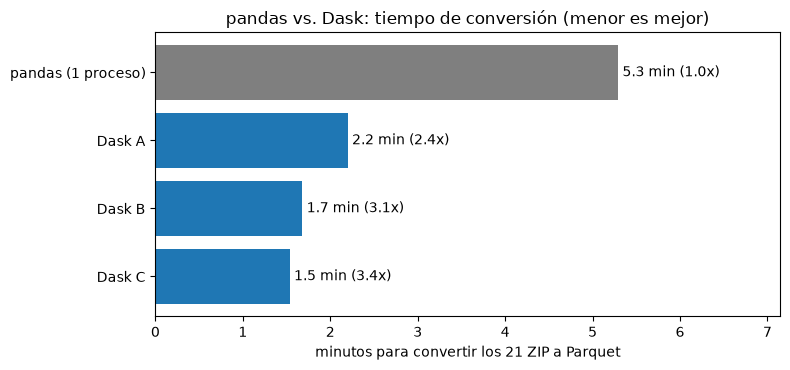

In [12]:
# QUÉ HACE: compara los cuatro métodos en una tabla y una gráfica, y guarda la tabla como evidencia para el documento.
# CÓMO: speedup = segundos de pandas / segundos del método; se comprueba que todos procesaron las mismas filas.
# QUÉ MIRAR: Dask más rápido que pandas en las tres configuraciones; más workers = más rápido, con rendimientos decrecientes.
import matplotlib.pyplot as plt

comparacion = pd.DataFrame(resultados)
comparacion['minutos'] = comparacion['segundos'] / 60
comparacion['veces_más_rápido'] = comparacion.loc[0, 'segundos'] / comparacion['segundos']
comparacion['mismas_filas_que_pandas'] = comparacion['filas'] == comparacion.loc[0, 'filas']
columnas = ['método', 'workers', 'hilos', 'memoria_por_worker', 'estado', 'minutos', 'veces_más_rápido',
            'pico_memoria_GB', 'parquet_GB', 'filas', 'mismas_filas_que_pandas']
display(comparacion[columnas].round(2))

Path('../docs').mkdir(exist_ok=True)
comparacion[columnas].round(3).to_csv('../docs/benchmark_dask.csv', index=False, encoding='utf-8')

fig, ax = plt.subplots(figsize=(8, 3.8))
colores = ['#7f7f7f', '#1f77b4', '#1f77b4', '#1f77b4']
ax.barh(comparacion['método'][::-1], comparacion['minutos'][::-1], color=colores[::-1])
for i, (m, v) in enumerate(zip(comparacion['minutos'][::-1], comparacion['veces_más_rápido'][::-1])):
    ax.text(m + 0.05, i, f"{m:.1f} min ({v:.1f}x)", va='center')
ax.set_xlabel('minutos para convertir los 21 ZIP a Parquet'); ax.set_xlim(0, comparacion['minutos'].max() * 1.35)
ax.set_title('pandas vs. Dask: tiempo de conversión (menor es mejor)')
plt.tight_layout(); plt.savefig('../docs/figs/benchmark_dask.png', dpi=110); plt.show()

## 5. El consolidado: la tabla de partida para todo el análisis

Hasta ahora las conversiones se hicieron en carpetas temporales solo para medir. Aquí se hace **una vez, de verdad**, con la configuración más rápida (**C**), y se guarda dentro del proyecto:

`data/processed/validaciones/`  →  21 archivos Parquet (uno por día) que se leen **como una sola tabla**.

Ese consolidado:

- guarda **las 22 columnas y las 31.5 millones de filas** (nada se descarta ni se modifica: la limpieza viene después, en el EDA),
- ocupa mucho menos que los datos originales (se comprueba abajo),
- se lee en segundos, así que **los demás notebooks ya no vuelven a abrir los ZIP**.

> Los datos de `data/` no se suben a GitHub (están en `.gitignore`).

In [13]:
# QUÉ HACE: genera el consolidado definitivo en data/processed/validaciones/ (un Parquet por día) con Dask, configuración C.
# CÓMO: abre el clúster C, reparte los 21 ZIP entre los workers (cada uno convierte los suyos por trozos) y lo cierra.
# QUÉ MIRAR: 21 archivos; 31,530,646 filas (igual que antes); el tamaño total (~1.3 GB) frente a los 10.3 GB del CSV.
CONSOLIDADO = Path('../data/processed/validaciones')
if CONSOLIDADO.exists():
    shutil.rmtree(CONSOLIDADO)                 # se rehace desde cero para no mezclar corridas
CONSOLIDADO.mkdir(parents=True)

cluster = LocalCluster(processes=True, dashboard_address=':8787', **CONFIG_C)
client = Client(cluster)
t0 = time.perf_counter()
try:
    filas_consolidado = sum(dask.compute(*[dask.delayed(convertir_dia)(str(z), str(CONSOLIDADO)) for z in ZIPS]))
finally:
    client.close()
    cluster.close()
segundos_consolidado = time.perf_counter() - t0

archivos = sorted(CONSOLIDADO.glob('*.parquet'))
peso = sum(a.stat().st_size for a in archivos) / 1e9
print(f"Consolidado listo en {segundos_consolidado:.0f} s: {len(archivos)} archivos Parquet | {filas_consolidado:,} filas | {peso:.2f} GB")
print(f"Frente a los datos originales: {inventario.zip_MB.sum() / 1e3:.2f} GB (ZIP) y {inventario.csv_MB.sum() / 1e3:.2f} GB (CSV) -> el Parquet pesa {inventario.csv_MB.sum() / 1e3 / peso:.1f} veces menos que el CSV")

C:\Users\Skanhawk\OneDrive - SKANHAWK\Escritorio\MAESTRIA EN ANALITICA\HERRAMIENTAS DE BIG DATA\Proyecto Final v2\venv\Lib\site-packages\distributed\node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 62764 instead
  warnings.warn(


Consolidado listo en 86 s: 21 archivos Parquet | 31,530,646 filas | 1.27 GB
Frente a los datos originales: 2.12 GB (ZIP) y 10.33 GB (CSV) -> el Parquet pesa 8.2 veces menos que el CSV


In [14]:
# QUÉ HACE: comprueba el consolidado: lo lee como UNA sola tabla y verifica filas, columnas y que no se perdió nada.
# CÓMO: dd.read_parquet lee la carpeta completa; las filas salen de los metadatos (instantáneo); luego se cuentan validaciones por fecha leyendo una sola columna.
# QUÉ MIRAR: 31,530,646 filas y 22 columnas (igual que los ZIP); el conteo por fecha tarda segundos y muestra las "colas de medianoche" (17-ago, 13-sep, 21-sep).
t0 = time.perf_counter()
tabla = dd.read_parquet(str(CONSOLIDADO))
filas_leidas = len(tabla)
print(f"Lectura como una sola tabla: {filas_leidas:,} filas, {len(tabla.columns)} columnas, {tabla.npartitions} particiones (tiempo {time.perf_counter() - t0:.1f} s)")
assert filas_leidas == filas_consolidado == resultados[0]['filas'], 'no coincide el número de filas'
assert len(tabla.columns) == 22, 'faltan columnas'

t0 = time.perf_counter()
por_fecha = tabla['Fecha_Transaccion'].str[:10].value_counts().compute().sort_index()
print(f"Validaciones por fecha (leyendo solo 1 columna de 22): {time.perf_counter() - t0:.1f} s")
display(por_fecha.rename('validaciones').to_frame())
print(f"Total: {por_fecha.sum():,} | fechas distintas: {len(por_fecha)} (21 días + 3 fechas con unas pocas validaciones de medianoche)")

Lectura como una sola tabla: 31,530,646 filas, 22 columnas, 21 particiones (tiempo 0.1 s)


Validaciones por fecha (leyendo solo 1 columna de 22): 1.2 s


,validaciones
Fecha_Transaccion,
2026-08-03,1817358
2026-08-04,1879861
2026-08-05,1893706
2026-08-06,1837051
2026-08-07,525834
2026-08-08,1062203
2026-08-09,516447
2026-08-10,1751957
2026-08-11,1832549


Total: 31,530,646 | fechas distintas: 24 (21 días + 3 fechas con unas pocas validaciones de medianoche)
